# Regularization

A model with many coefficients can fit its training data closely, but still predict new data poorly. Flexibility allows the model to adapt to the unexplainable noise along with the signal. 

**Ridge Regression** trades an increase in model bias (the model is on average a little wrong) for a decrease in model variance (the model is less sensitive to the data). This is accomplished by penalizing the size of the estimated coefficients, so that, all else equal, the fit model prefers smaller ones. A parameter `α`, set at model construction, controls the severity of the penalty.

Ridge Regression has another nice quality: it allows for rank deficient design matrices. In the extreme case of duplicated predictors, ridge gives each an equal estimated coefficient, instead of failing. 

This notebook works through using `py-glm` to fit and inspect ridge regressions. We'll cover:

- a model with many correlated predictors, which *overfits*,
- the ridge penalty, and how it improves predictions on new data,
- the **regularization path**: which fits ridge regressions over a range of penalty strengths,
- choosing the penalty strength by **cross-validation**, and
- what is, and isn't, available for inference on ridge models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glm.datasets import make_frame
from glm.families import QuasiPoisson
from glm.glm import GLM
from glm.plotting import plot_coefficient_paths, plot_cv_deviance
from glm.ridge import RidgePath, RidgePathCV

## Overfitting

Here are counts from a Poisson model with a sizable number of predictors, many of them strongly correlated, and small coefficients. We also let some latent noise enter into determining the outcome, this is random variation that none of our predictors can capture. So we both have the usual sampling noise in `y | X`, and also additional noise due to the missing predictors. We use the `QuasiPoisson` family to account for the additional variance not captured in the Poisson distribution of `y | X`.

Since our data is simulated, we know the true data generating process, so can also draw as much *test* data from the same process as we like. This allows us to measure how well a model really predicts new data, rather than estimating it. We draw a very large test set, so our measurements of model performance are very close to the population values.

In [2]:
n_train = 500
n_test = 20_000

sim = make_frame(
    QuasiPoisson(),
    n_samples=n_train + n_test,
    n_uncorrelated=10,
    n_correlated=50,
    correlation=0.8,
    coef_range=(-0.3, 0.3),
    latent_noise_sd=1.0,
    rng=np.random.default_rng(11),
)
train = sim.data.iloc[:n_train]
test = sim.data.iloc[n_train:]
formula = sim.formula
formula

'y ~ x1 + x2 + x3 + x4 + x5 + x6 + x7 + x8 + x9 + x10 + x11 + x12 + x13 + x14 + x15 + x16 + x17 + x18 + x19 + x20 + x21 + x22 + x23 + x24 + x25 + x26 + x27 + x28 + x29 + x30 + x31 + x32 + x33 + x34 + x35 + x36 + x37 + x38 + x39 + x40 + x41 + x42 + x43 + x44 + x45 + x46 + x47 + x48 + x49 + x50 + x51 + x52 + x53 + x54 + x55 + x56 + x57 + x58 + x59 + x60'

We measure fit by the **deviance per observation**: the deviance, the GLM's measure of lack of fit, averaged over the observation count. Lower is better. 

On the training data, deviance measures how closely the model fits the data it has seen. On the test data, how well the model *actually does*, i.e., how well we expect it to predict a random datapoint chosen fresh from the same data generating process.

In [3]:
def deviance_per_observation(model, data):
    """A model's average unit deviance on a data frame."""
    y = data["y"].to_numpy()
    # Note: This is only correct when no sample weighting is used.
    return model.family.deviance(y, model.predict(data)) / len(data)

First we'll fit a model with no ridge penalization, the **unpenalized** model.

In [4]:
unpenalized = GLM(QuasiPoisson()).fit(train, formula=formula)

pd.Series(
    {
        "train": deviance_per_observation(unpenalized, train),
        "test": deviance_per_observation(unpenalized, test),
    },
    name="deviance per observation",
).round(3)

train    2.565
test     4.079
Name: deviance per observation, dtype: float64

The model fits its training data far better than it predicts new data.

Now, almost any fitted model looks better on the fitting data than an unseen sample, so just the presence of a gap doesn't tell us so much. What matters is whether a less flexible model from the collection of models we're considering would predict new data better. If one does, we say the unpenalized model is *overfit*, and we'll see below that this one is.

## The ridge penalty

A ridge penalized GLM minimizes the deviance *plus* a penalty on the size of the coefficients:

```
D(β) + α Σⱼ βⱼ²
```

The penalty strength `α` sets the trade-off: at `α = 0` we have the unpenalized fit; as `α` grows minimizing the penalized deviance requires fit to the data less and small coefficients more. That is, as `α` grows the estimated coefficients are pulled toward zero. 

The intercept is never penalized, the sum is over `j >= 1`, so the most heavily penalized models predict the constant mean of `y`.

A penalty on the coefficients introduces dependency on the predictors' units, whereas an unpenalized model is invariant to affine transformation of the predictors. With a penalty though, measure a predictor in metres rather than kilometres, and its coefficient shrinks a thousandfold. This sort of unit dependence is undesirable, so it is conventional for ridge regression to employ some sort of standardization practice to ensure unitless predictors. 

We offer a few options in `py-glm`:

  - Standardize only the continuous predictors, leave any category indicators alone as they are by nature unitless.
  - Standardize all the predictors, even the category indicators.
  - Standardize no predictors, in case the user wants to employ their own strategy.

The default is the first, we standardize the non-binary predictors. In any case, estimated coefficients are reported on their *original* scale, before any internal standardization. 

Let's look at fitting a few ridge models at various regularization strengths, to get a feel for what happens:

In [5]:
ALPHAS = [0.0, 1.0, 10.0, 100.0, 1_000.0, 10_000.0]

results = {}
for alpha in ALPHAS:
    model = GLM(QuasiPoisson(), alpha=alpha).fit(train, formula=formula)
    results[alpha] = {
        "train": deviance_per_observation(model, train),
        "test": deviance_per_observation(model, test),
    }

pd.DataFrame(results).T.rename_axis("alpha").round(3)

,train,test
alpha,,
0.0,2.565,4.079
1.0,2.566,4.067
10.0,2.569,3.974
100.0,2.695,3.672
1000.0,3.368,3.796
10000.0,3.953,4.136


As `α` grows, the training deviance can only increase: the penalty pulls the fit away from the coefficients that fit the training data best. But the test deviance first *falls*, as the penalty dampens the variance in the estimates, and rises again once the penalty is so strong that it also removes the real effects. 

So the unpenalized model is overfit: less flexible models from the same family predict new data better.

Somewhere in between is a penalty strength that predicts best. This suggests a cross-validation procedure for determining the ideal `α`.

## The regularization path

Rather than fitting one penalty strength at a time, a `RidgePath` fits a whole grid of them, from a penalty so strong that every estimated coefficient is nearly zero, down to one so weak that the fit is essentially unpenalized. You can supply your own grid, but otherwise the grid is determined from an analysis of the data (based on an eigenvalue decomposition of the information matrix, see `default_alphas` for details). Letting `RidgePath` determine its own grid is the suggested procedure.

Each fit starts from the previous one's estimated coefficients, which makes fitting the entire path efficient:

In [6]:
path = RidgePath(QuasiPoisson()).fit(train, formula=formula)
path.coefficient_table().iloc[::20, :6].rename(index="{:.3g}".format).round(3)

,Intercept,x1,x2,x3,x4,x5
alpha,,,,,,
4.13e+06,0.719,-0.000,0.000,-0.000,-0.000,-0.000
1.91e+05,0.717,-0.001,0.000,-0.001,-0.001,-0.002
8.86e+03,0.661,-0.010,0.006,-0.019,-0.021,-0.030
410,0.554,-0.051,0.037,-0.137,-0.158,-0.185
19,0.324,-0.076,0.056,-0.193,-0.218,-0.231


`plot_coefficient_paths` draws each estimated coefficient as the penalty varies. With this many predictors, one color per predictor is a mess, so here we group the estimated coefficients by the sign of their true value, using the `groups` argument. By default, the estimated coefficients are plotted *standardized*, as the penalty sees them.

The horizontal axis can be the penalty strength, `α`, or the model's **effective degrees of freedom**, which is a measure of model complexity in one-to-one correspondence with `α`, but closer in interpretation to the coefficient count. 

An unpenalized model spends one degree of freedom on each penalized coefficient, so its effective degrees of freedom is the count of penalized coefficients (i.e., the intercept is not counted). An eigenvalue analysis shows that ridge shrinks the estimated coefficients along each eigen-direction of the information matrix by a factor `d / (d + α)`, where `d` is that direction's eigenvalue (exactly true for a Gaussian model, approximately for more general GLMs). The effective degrees of freedom sums these shrinkage factors: it runs from 0, with every estimated coefficient shrunk away, to the count of penalized coefficients, with no shrinkage at all. 

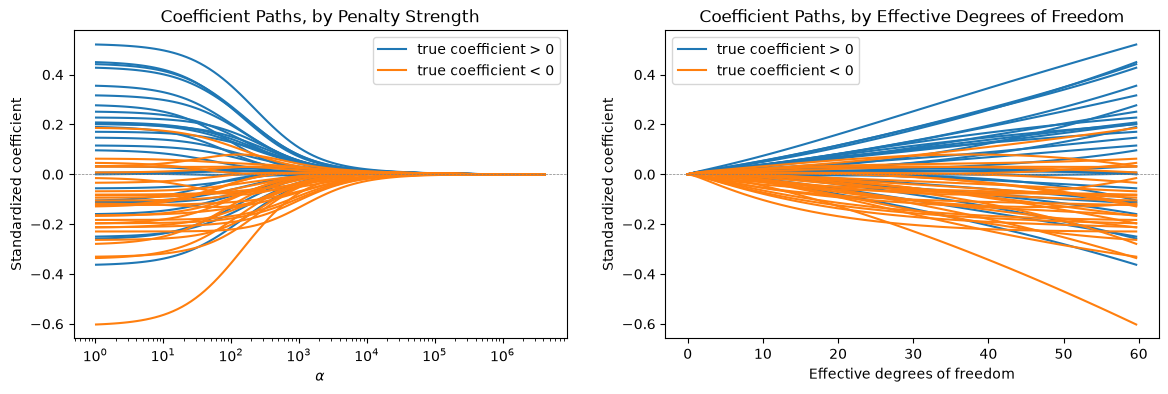

In [7]:
positive = [name for name in sim.coef.index[1:] if sim.coef[name] > 0]
negative = [name for name in sim.coef.index[1:] if sim.coef[name] <= 0]
groups = {"true coefficient > 0": positive, "true coefficient < 0": negative}

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
plot_coefficient_paths(axs[0], path, groups=groups)
plot_coefficient_paths(axs[1], path, groups=groups, x="df")
axs[0].set_title("Coefficient Paths, by Penalty Strength")
axs[1].set_title("Coefficient Paths, by Effective Degrees of Freedom");

Reading right to left on the first plot, or left to right on the second: as the penalty relaxes, the estimated coefficients grow from zero, at first mostly in the direction of their true values, and then, as the fit approaches the unpenalized one, spreading out, and crossing over each other, as the noise takes over.

At first look, it may seem like each estimated coefficient travels a monotonic path to its final, unpenalized, value, but close inspection should reveal this is not the case. Non-monotonicity is due to the correlation structure within the associated predictors. When two predictors are strongly correlated to one another, it may be beneficial to use "only" the predictor most correlated to the target when the penalty is strong, but "both" when the penalty is relaxed.

Since we have test data, we can assess how well each model on the path really predicts:

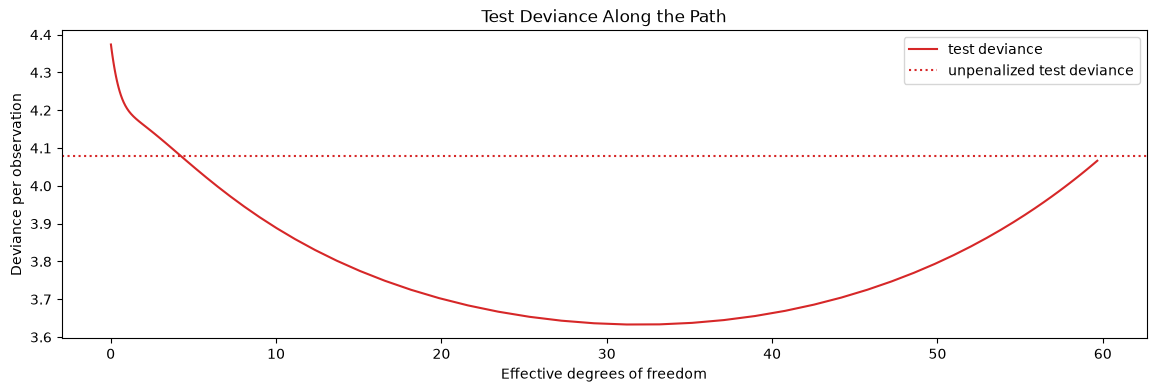

In [8]:
def plot_test_deviance(ax, path, test, unpenalized):
    """Each model's test deviance per observation along a path, against
    its effective degrees of freedom."""
    test_deviance = np.array([deviance_per_observation(model, test) for model in path.models_])
    ax.plot(path.df_, test_deviance, color="C3", label="test deviance")
    ax.axhline(
        deviance_per_observation(unpenalized, test),
        color="C3",
        linestyle=":",
        label="unpenalized test deviance",
    )
    ax.set_xlabel("Effective degrees of freedom")
    ax.set_ylabel("Deviance per observation")
    ax.legend()
    return ax


fig, ax = plt.subplots(figsize=(14, 4))
plot_test_deviance(ax, path, test, unpenalized)
ax.set_title("Test Deviance Along the Path");

The test deviance has a strong U-shape (it should be noted that we chose data generation parameters to enhance this effect, in natural data it is often rather weaker and can be non-U-shaped). The unpenalized model performs rather worse than models somewhere in the interior. This is usually explained using the **bias-variance decomposition** of the expected error:

```
E[test error] = bias² + variance + irreducible error
```

A full explanation would take us too far from our main points, but qualitatively:

  - The **bias** quantifies how far the fit model's average fit is from the true data generating process (across sampled training datasets of the same size drawn from the same random process).
  - The **variance** quantifies how much the fit model varies depending on the random noise in the training data.
  - The **irreducible error** is the true noise in the data that cannot be reduced by a model.

The expected test error decomposition is exact for the Gaussian family, and there is a generalization to more general exponential families.

The idea of regularization in general is that penalization increases the bias while decreasing the variance, but these competing factors occur at different rates as `α` is varied. The decrease in variance dominates the increase in bias for a while, so we'll find a value of penalization that improves the test error.

On the face of it, we could achieve the same qualitative effect by removing weak predictors outright, and this is commonly done. But this is a rather violent, all-or-nothing intervention, and it is known that *which* weak predictor is dropped is rather sensitive to noise. The smooth relaxing of penalty enabled by ridge regression allows a compromise, and this smooth tuning of effective degrees of freedom is extremely useful in practice.

## Choosing the penalty by cross-validation

Of course, in natural data we will not have the blessing of a large independent sample from our population so as to draw the "true" test deviance along the regularization path. We need some facsimile of this procedure.

**Cross-validation** is a clever solution to this problem. The training data are split into *folds* of equal size, here we use 10 folds, anything from five to ten is common practice. 

We fit the model ten times. Each fold in turn is held out from the model fitting, a regularization path is fit to the other nine, and each model on it is scored by its deviance on the held-out fold. This gives an `n-folds × n-alphas` array of test deviance estimates. Averaging over the folds gives an estimate of the test deviance at every penalty strength. 

`RidgePathCV` does all of this, with every fold's path fit over the same grid of penalty strengths:

In [9]:
cv = RidgePathCV(QuasiPoisson(), n_folds=10).fit(
    train, formula=formula, rng=np.random.default_rng(6)
)

`plot_cv_deviance` gives a visual overview of the `α` selection information, showing the test deviance estimated through cross validation, and the standard error of those estimates for each `α`:

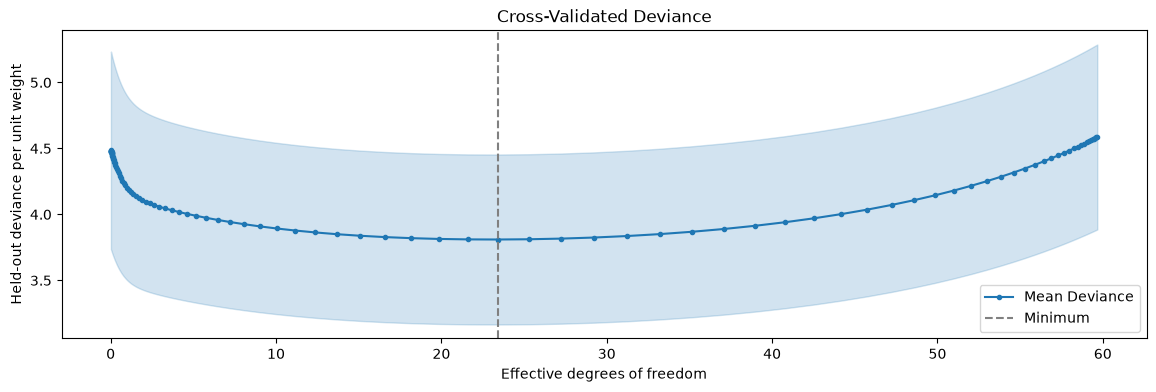

In [10]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_cv_deviance(ax, cv, x="df")
ax.set_title("Cross-Validated Deviance");

The standard error bars are often wide, which is in evidence here. There's often a large variation in the "difficulty" of each cross validation fold. On the other hand, the *shape* of the curve tends to be more stable across folds. Below we show the deviances of the individual folds and it is evident that they vary quite a bit in difficulty:

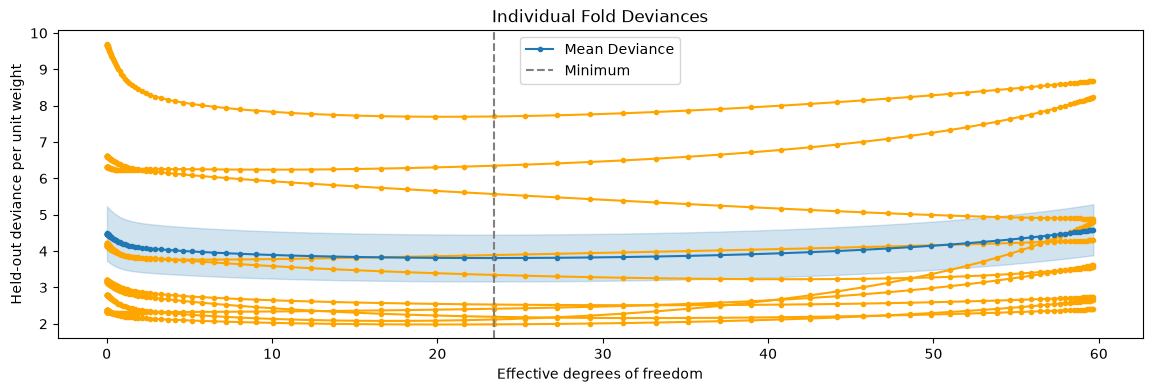

In [11]:
fig, ax = plt.subplots(figsize=(14, 4))

for folddev in cv.fold_deviances_:
    ax.plot(cv.path_.df_, folddev, color='orange', marker=".")

plot_cv_deviance(ax, cv, x="df")

ax.set_title("Individual Fold Deviances");

Since we have a large test set on hand, we can compare the estimate from cross validation to the actual test deviance:

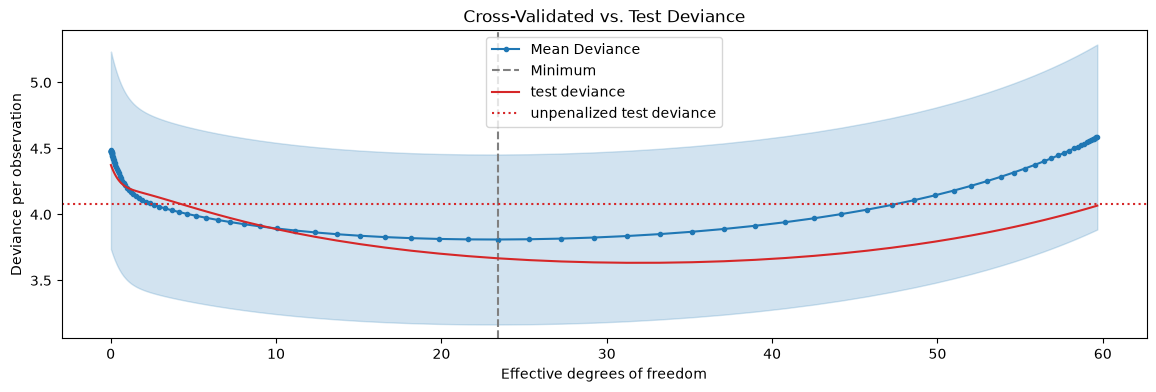

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_cv_deviance(ax, cv, x="df")
plot_test_deviance(ax, cv.path_, test, unpenalized)
ax.set_title("Cross-Validated vs. Test Deviance");

The cross-validated deviance tracks the U-shape of the test deviance well. Its level is a little off, sometimes lower or higher than the truth. What matters for choosing the penalty is the shape, not the level, so this is no trouble to the method. The minimum of the estimate is a little more conservative than the true minimum, but this is not always the case.

Now we can compare the model chosen through cross validation to the unpenalized model on the true test data:

In [13]:
models = {
    "unpenalized": unpenalized,
    f"alpha_min_ = {cv.alpha_min_:.3g}": cv.model_min_,
}
pd.Series(
    {name: deviance_per_observation(model, test) for name, model in models.items()},
    name="test deviance per observation",
).round(3)

unpenalized         4.079
alpha_min_ = 410    3.667
Name: test deviance per observation, dtype: float64

As expected, the penalized model does better.

### Cross-validation with weights

`RidgePathCV` takes frequency and precision weights, as `GLM.fit` does, and splits the data into folds with care for what each kind of weight means (see the weights notebook). A row with frequency weight `f` stands for `f` separate observations, so they're dealt out to the folds separately, exactly as if the data were expanded to one row per observation. A precision-weighted row is a single observation, of an average, so it's held out whole. Each fold's held-out deviance is weighted the same way as the fit's.

## Coefficients and inference

The penalized model's estimated coefficients are *biased* toward zero, by design: ridge regression is intentionally a biased estimator. This makes the theory of inference for ridge more complicated than for unpenalized models, so for now, standard errors, covariances and p-values raise an error for regularized models, and `summary_frame` reports only the estimates:

In [14]:
try:
    cv.model_min_.coef_standard_error_
except ValueError as error:
    print(error)

cv.model_min_.summary_frame().head()

Standard errors, covariances and p-values are not available for regularized models: the penalty biases the estimates, so intervals built from their sampling variance don't cover the true coefficients. Use the bootstrap (see Simulation) for the variability of a ridge fit.


,estimate
Intercept,0.553965
x1,-0.051060
x2,0.036637
x3,-0.137240
x4,-0.158177
